# 04 - Benchmark: error vs SNR

`python scripts/run_benchmark.py` repeats the analysis over many noise realisations at several distances (hence SNRs)
and writes `results/benchmark.csv`. Here we load it and plot the errors.

* **lag error** = mean over detector pairs of |lag(method) - lag(noise-free signal)|
* **merger-time error** = |t$_{peak}$ - t$_c$|

In [1]:
import numpy as np, matplotlib.pyplot as plt
from gwhht.benchmark import load_csv, summarize
from gwhht.plotting import plot_error_vs_snr
from gwhht.config import load_config
%matplotlib inline

cfg = load_config("../configs/default.yaml")
rows = load_csv("../results/benchmark.csv")
summ = summarize(rows, [a + b for a, b in cfg.pairs()])
print(f"{len(rows)} runs, {len({r['distance'] for r in rows})} distances")

210 runs, 7 distances


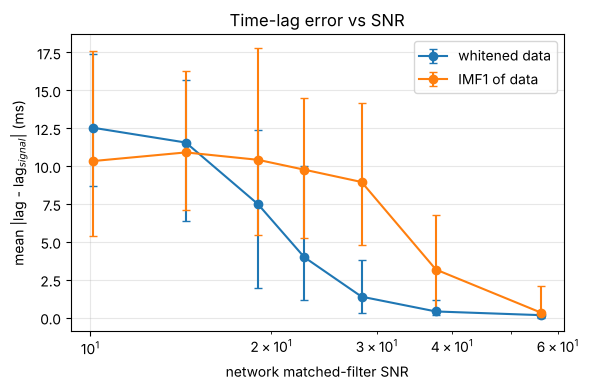

In [2]:
plot_error_vs_snr(summ, [("lag_data", "whitened data"), ("lag_imf1", "IMF1 of data")],
                  "Time-lag error vs SNR", "mean |lag - lag$_{signal}$| (ms)")
plt.show()

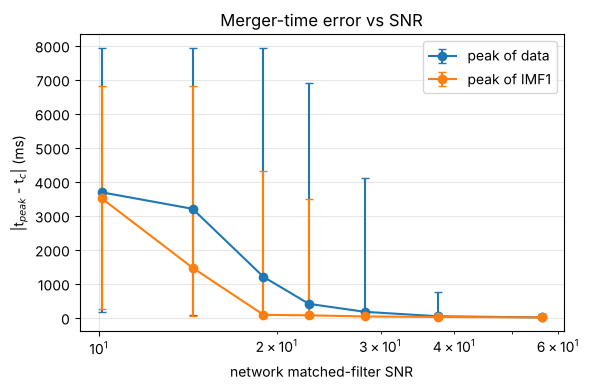

In [3]:
plot_error_vs_snr(summ, [("merger_peak", "peak of data"), ("merger_imf1", "peak of IMF1")],
                  "Merger-time error vs SNR", "|t$_{peak}$ - t$_c$| (ms)")
plt.show()

In [4]:
print(f"{'dist':>6s} {'SNR':>6s} {'lag data':>10s} {'lag IMF1':>10s} {'mrg data':>10s} {'mrg IMF1':>10s}   (medians, ms)")
for s in summ:
    print(f"{s['distance']:6.0f} {s['snr']:6.1f} {s['lag_data'][0]:10.2f} {s['lag_imf1'][0]:10.2f} "
          f"{s['merger_peak'][0]:10.2f} {s['merger_imf1'][0]:10.2f}")

  dist    SNR   lag data   lag IMF1   mrg data   mrg IMF1   (medians, ms)
   200   56.2       0.16       0.33       7.56       7.56
   300   37.6       0.41       3.17      41.25      20.99
   400   28.3       1.38       8.95     171.38      36.61
   500   22.7       3.99       9.77     406.25      68.84
   600   19.0       7.49      10.42    1200.43      84.22
   800   14.4      11.56      10.90    3200.92    1467.77
  1200   10.1      12.53      10.34    3687.25    3511.71
